In [9]:
import os
from collections import Counter

import kagglehub
import torch
import torchvision
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

In [10]:
#Pobranie i lokaliacja zbioru danych

# Automatyczne pobranie zbioru z platformy Kaggle
download_path = kagglehub.dataset_download("dineshpiyasamara/geometric-shapes-dataset")

# Odnalezienie ścieżki do plików graficznych w pobranym archiwum
all_images = []
for root, dirs, files in os.walk(download_path):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp')):
            all_images.append(os.path.join(root, file))

if not all_images:
    raise FileNotFoundError("Nie znaleziono plików graficznych w pobranym katalogu.")

# Wyznaczenie ścieżki do przykładowego obrazu i katalogu głównego (wymaganego przez ImageFolder)
sample_image_path = all_images[0]
sample_class_dir = os.path.dirname(sample_image_path)
dataset_dir = os.path.dirname(sample_class_dir)

Using Colab cache for faster access to the 'geometric-shapes-dataset' dataset.


In [11]:
#DEFINICJA POTOKÓW TRANSFORMACJI

# Wariant ewaluacyjny: brak augmentacji, tylko standaryzacja
eval_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

# Wariant treningowy: dodana augmentacja zwiększająca różnorodność danych
train_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomRotation(45),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor()
])

In [12]:
#UTWORZENIE ZBIORÓW DANYCH I DATALOADERÓW

# Inicjalizacja struktury ImageFolder
train_dataset = datasets.ImageFolder(root=dataset_dir, transform=train_transform)
eval_dataset = datasets.ImageFolder(root=dataset_dir, transform=eval_transform)

# Utworzenie DataLoaderów paczkujących dane (batch_size=8)
train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
eval_loader = DataLoader(eval_dataset, batch_size=8, shuffle=False)

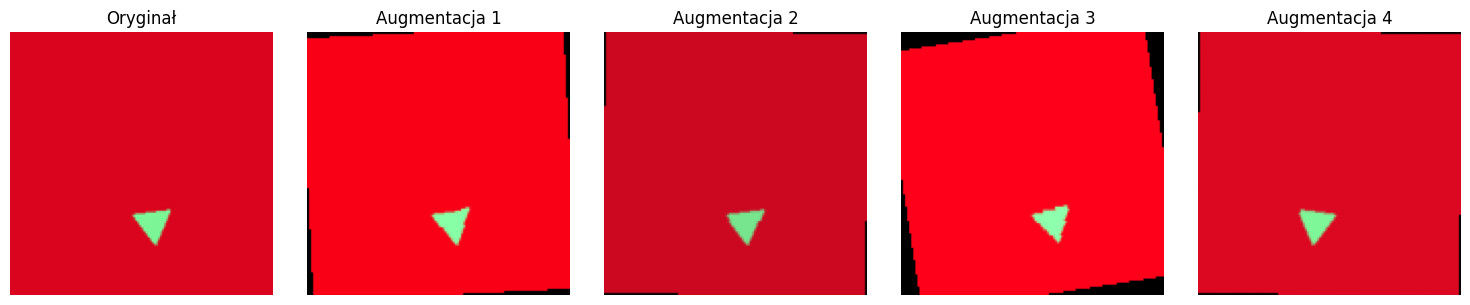

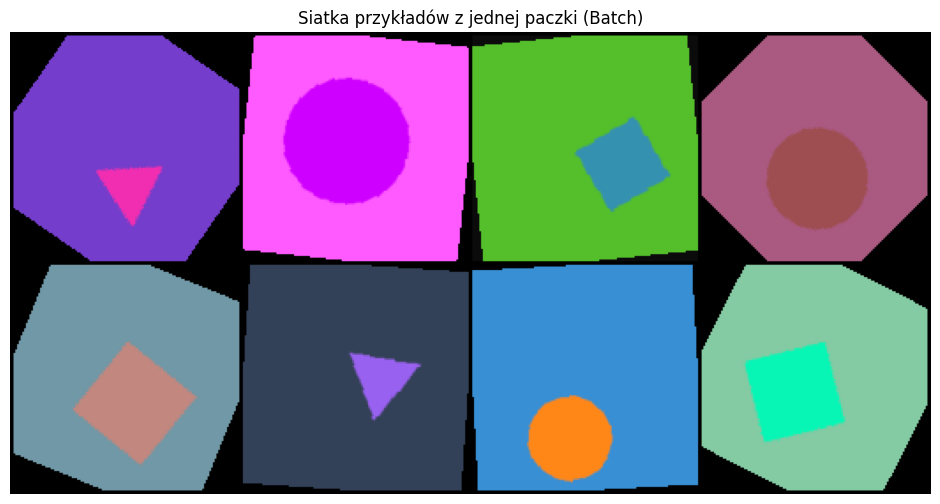

In [13]:
#WIZUALIZACJE
# Podgląd działania augmentacji na jednym obrazie
sample_image = Image.open(sample_image_path).convert('RGB')
fig, axes = plt.subplots(1, 5, figsize=(15, 3))

# Wyświetlenie oryginału
axes[0].imshow(sample_image.resize((128, 128)))
axes[0].set_title("Oryginał")
axes[0].axis('off')

# Wyświetlenie 4 niezależnych losowych transformacji
for i in range(1, 5):
    augmented_tensor = train_transform(sample_image)
    augmented_image = augmented_tensor.permute(1, 2, 0).numpy()

    axes[i].imshow(augmented_image)
    axes[i].set_title(f"Augmentacja {i}")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

#Siatka przykładów z jednej paczki (batcha)
images, labels = next(iter(train_loader))
grid = torchvision.utils.make_grid(images, nrow=4)

plt.figure(figsize=(12, 6))
plt.imshow(grid.permute(1, 2, 0).numpy())
plt.title("Siatka przykładów z jednej paczki (Batch)")
plt.axis('off')
plt.show()

In [14]:
#STATYSTYKI ZBIORU
print("\n--- SZCZEGÓŁOWE STATYSTYKI ZBIORU ---")
print(f"Liczba klas: {len(train_dataset.classes)}")
print(f"Rozmiar tensora po transformacji: {images[0].shape}")
print(f"Mapowanie klas na indeksy (class_to_idx): {train_dataset.class_to_idx}")

class_counts = Counter([label for _, label in train_dataset.samples])
for class_idx, count in class_counts.items():
    class_name = train_dataset.classes[class_idx]
    print(f"Liczba obrazów w klasie '{class_name}': {count}")


--- SZCZEGÓŁOWE STATYSTYKI ZBIORU ---
Liczba klas: 3
Rozmiar tensora po transformacji: torch.Size([3, 128, 128])
Mapowanie klas na indeksy (class_to_idx): {'Circle': 0, 'Square': 1, 'Triangle': 2}
Liczba obrazów w klasie 'Circle': 10000
Liczba obrazów w klasie 'Square': 10000
Liczba obrazów w klasie 'Triangle': 10000
